# **CNN on CIFAR-10 Dataset**

This notebook demonstrates how to preprocess the CIFAR-10 dataset, build a Convolutional Neural Network (CNN) model using Keras, and visualize the model's training and validation behavior, including error loss, training and validation loss, and accuracy.

---




## **1. Importing Libraries**

We'll start by importing the necessary libraries, including TensorFlow, Keras, and Matplotlib for plotting.

In [1]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt

## **2. Loading and Preprocessing the CIFAR-10 Dataset**

The CIFAR-10 dataset consists of 60,000 32x32 color images in 10 different classes. We'll load the dataset and normalize the pixel values to be between 0 and 1.


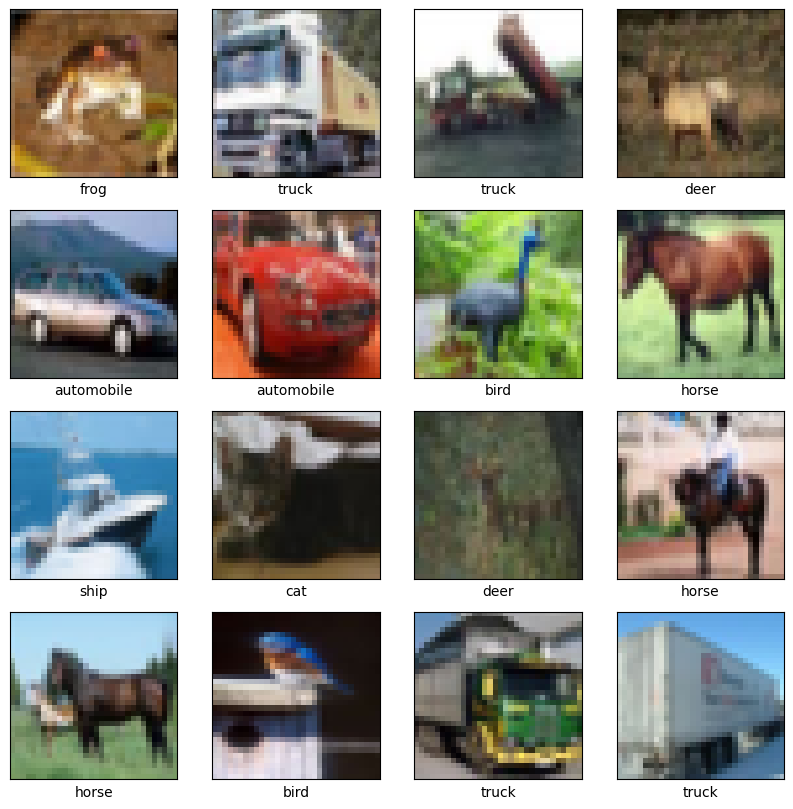

In [2]:
# Load the CIFAR-10 dataset
(train_images, train_lables), (test_images, test_lables)=datasets.cifar10.load_data()
# Normalize the pixel value between 0 and 1

train_images= train_images/255
test_images=test_images/255

# Display a few sample images with labels
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

plt.figure(figsize=(10,10))

for i in range(16):
  plt.subplot(4, 4, i+1)
  plt.xticks([])
  plt.yticks([])
  plt.grid(False)
  plt.imshow(train_images[i], cmap=plt.cm.binary)
  plt.xlabel(class_names[train_lables[i][0]])
plt.show()


## **3. Building the CNN Model**

We'll build a CNN model with three convolutional layers, followed by pooling layers, and then fully connected layers for classification.


In [ ]:
# Build the CNN model
model=models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64,(3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64,(3,3), activation='relu'),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10)
])

# Display the model artitecture summary
model.summary()

c:\Users\LENOVO\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,570 (478.79 KB)

 Trainable params: 122,570 (478.79 KB)

 Non-trainable params: 0 (0.00 B)

## **4. Compiling and Training the Model**

We'll compile the model using the Adam optimizer and Sparse Categorical Crossentropy loss. Then, we'll train the model for 10 epochs and store the training history.


In [4]:
# complie the model
model.compile(optimizer='adam',
              loss=tf.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

#applying early stopping

early_stopping = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=2)

# train the model
history=model.fit(train_images, train_lables, epochs=10,
                  validation_data=(test_images, test_lables))

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step - accuracy: 0.1838 - loss: 2.1618 - val_accuracy: 0.2607 - val_loss: 1.9155
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.2888 - loss: 1.8624 - val_accuracy: 0.3819 - val_loss: 1.6699
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 18s 12ms/step - accuracy: 0.4169 - loss: 1.6146 - val_accuracy: 0.4560 - val_loss: 1.4958
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.4920 - loss: 1.4317 - val_accuracy: 0.4983 - val_loss: 1.4072
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 20s 13ms/step - accuracy: 0.5441 - loss: 1.2943 - val_accuracy: 0.5529 - val_loss: 1.2741
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 39s 25ms/step - accuracy: 0.5788 - loss: 1.2011 - val_accuracy: 0.5545 - val_loss: 1.2492
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 39s 25ms/step - accuracy: 0.6051 - loss: 1.1173 - val_accuracy: 0.5868 - val_loss: 1.1772
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 41s 26ms/step - accuracy: 0.6259 -

## **5. Evaluating the Model**

After training, we'll evaluate the model's performance on the test set and display the test accuracy.


In [5]:
# Evaluate the model on the test set
test_loss, test_acc = model.evaluate(test_images, test_lables, verbose=2)
print(f'\nTest accuracy: {test_acc}')

313/313 - 1s - 4ms/step - accuracy: 0.5948 - loss: 1.1462

Test accuracy: 0.5947999954223633


## **6. Plotting the Training and Validation Metrics**

Finally, we'll plot the training and validation loss, as well as the training and validation accuracy, to visualize the model's performance over the epochs.


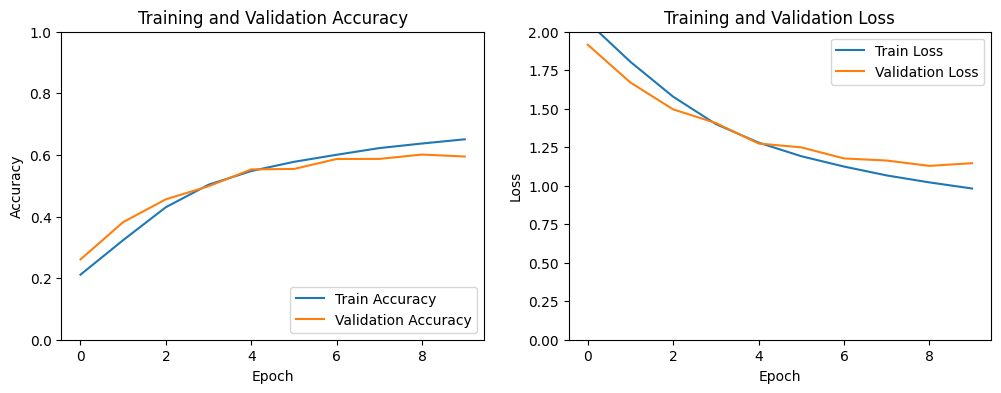

In [6]:
# Plot training & validation accuracy values
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label = 'Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0, 1])
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

# Plot training & validation loss values
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.ylim([0, 2])
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')

plt.show()


## **7. Visualizing Some Predictions**

We will visualize some predictions made by the trained model on the test set. We'll display the images along with the predicted and true labels.


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


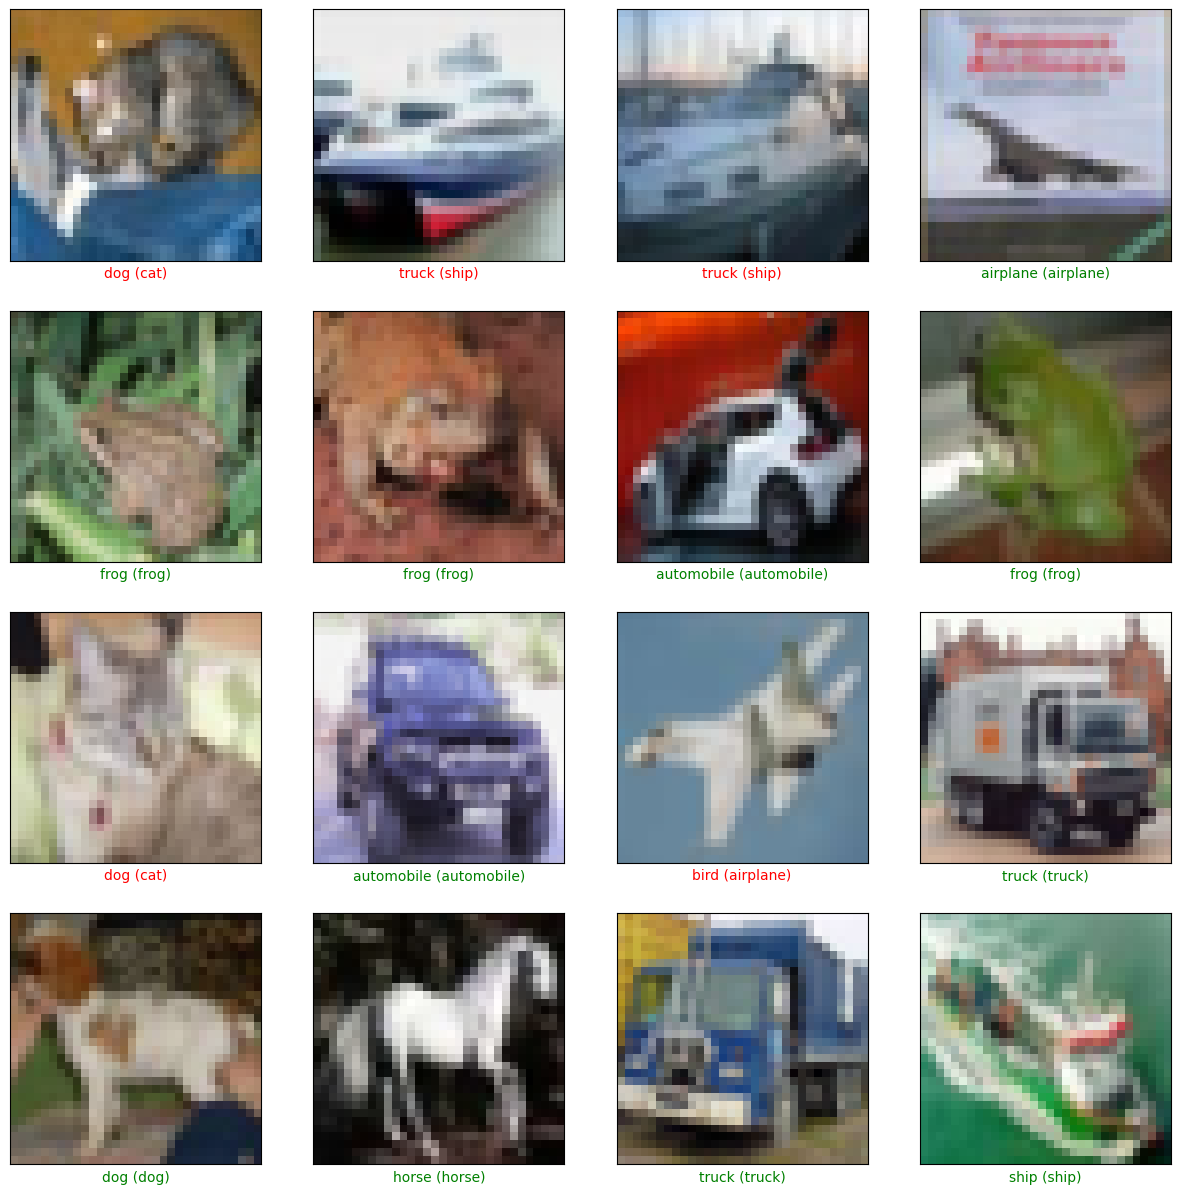

In [7]:
import numpy as np

# Make predictions on the test set
predictions = model.predict(test_images)

# Function to plot images with predictions
def plot_images_with_predictions(images, labels, predictions, class_names):
    plt.figure(figsize=(15,15))
    for i in range(16):
        plt.subplot(4, 4, i+1)
        plt.xticks([])
        plt.yticks([])
        plt.grid(False)
        plt.imshow(images[i], cmap=plt.cm.binary)
        predicted_label = np.argmax(predictions[i])
        true_label = labels[i][0]
        color = 'green' if predicted_label == true_label else 'red'
        plt.xlabel(f"{class_names[predicted_label]} ({class_names[true_label]})", color=color)
    plt.show()

# Visualize predictions on the first 16 images in the test set
plot_images_with_predictions(test_images, test_lables, predictions, class_names)


## **8. Conclusion**

In this notebook, we've built and trained a Convolutional Neural Network (CNN) to classify images from the CIFAR-10 dataset. We visualized the model's training and validation accuracy and loss to assess its performance. The model achieved a good test accuracy, but further tuning and optimization might improve the results even further.
